In [1]:
import os
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt

path = kagglehub.dataset_download("arashnic/book-recommendation-dataset")
# ver quais arquivos vieram
print(os.listdir(path))

books = pd.read_csv(os.path.join(path, "Books.csv"))
ratings = pd.read_csv(os.path.join(path, "Ratings.csv"))
users = pd.read_csv(os.path.join(path, "Users.csv"))

print(books.head())

c:\Users\user\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\user\AppData\Local\Temp\ipykernel_20896\1063267053.py:10: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  books = pd.read_csv(os.path.join(path, "Books.csv"))


         ISBN                                         Book-Title  \
0  0195153448                                Classical Mythology   
1  0002005018                                       Clara Callan   
2  0060973129                               Decision in Normandy   
3  0374157065  Flu: The Story of the Great Influenza Pandemic...   
4  0393045218                             The Mummies of Urumchi   

            Book-Author Year-Of-Publication                   Publisher  \
0    Mark P. O. Morford                2002     Oxford University Press   
1  Richard Bruce Wright                2001       HarperFlamingo Canada   
2          Carlo D'Este                1991             HarperPerennial   
3      Gina Bari Kolata                1999        Farrar Straus Giroux   
4       E. J. W. Barber                1999  W. W. Norton &amp; Company   

                                         Image-URL-S  \
0  http://images.amazon.com/images/P/0195153448.0...   
1  http://images.amazon.com/

In [ ]:
#filtrando fora as colunas de URL de imagem
pd.set_option('display.max_columns', None)
books[["ISBN", "Book-Title", "Book-Author", "Year-Of-Publication"]].head()

,ISBN,Book-Title,Book-Author,Year-Of-Publication
0,0195153448,Classical Mythology,Mark P. O. Morford,2002
1,0002005018,Clara Callan,Richard Bruce Wright,2001
2,0060973129,Decision in Normandy,Carlo D'Este,1991
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999


In [ ]:
pd.set_option('display.max_columns', None)
print(books.shape, ratings.shape, users.shape)
books.info()
books.isnull().sum()

(271360, 8) (1149780, 3) (278858, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271360 entries, 0 to 271359
Data columns (total 8 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   ISBN                 271360 non-null  object
 1   Book-Title           271360 non-null  object
 2   Book-Author          271358 non-null  object
 3   Year-Of-Publication  271360 non-null  object
 4   Publisher            271358 non-null  object
 5   Image-URL-S          271360 non-null  object
 6   Image-URL-M          271360 non-null  object
 7   Image-URL-L          271357 non-null  object
dtypes: object(8)
memory usage: 16.6+ MB


ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0
Image-URL-L            3
dtype: int64

In [ ]:
pd.set_option('display.max_columns', None)

# visão geral rápida
print("Books:", books.shape)
print("Ratings:", ratings.shape)
print("Users:", users.shape)

Books: (271360, 8)
Ratings: (1149780, 3)
Users: (278858, 3)


In [ ]:
print("Nulos em Books:\n", books.isnull().sum())
print("\nNulos em Ratings:\n", ratings.isnull().sum())
print("\nNulos em Users:\n", users.isnull().sum())

Nulos em Books:
 ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0
Image-URL-L            3
dtype: int64

Nulos em Ratings:
 User-ID        0
ISBN           0
Book-Rating    0
dtype: int64

Nulos em Users:
 User-ID          0
Location         0
Age         110762
dtype: int64


In [ ]:
#verificando quais colunas usuarios tem
users.head()

,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN


In [ ]:
#verificando quais colunas ratings tem
ratings.head()

,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


In [ ]:
#verificando quais colunas books tem
#books.head()
#bookssm = books sem as tabelas de imagens
bookssm = books[["ISBN", "Book-Title", "Book-Author", "Year-Of-Publication"]]
bookssm.head()

,ISBN,Book-Title,Book-Author,Year-Of-Publication
0,0195153448,Classical Mythology,Mark P. O. Morford,2002
1,0002005018,Clara Callan,Richard Bruce Wright,2001
2,0060973129,Decision in Normandy,Carlo D'Este,1991
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999


# INCONGRUENCIAS


In [ ]:
users['Age'].describe()

count    168096.000000
mean         34.751434
std          14.428097
min           0.000000
25%          24.000000
50%          32.000000
75%          44.000000
max         244.000000
Name: Age, dtype: float64

In [ ]:
users['Age'].unique()

array([ nan,  18.,  17.,  61.,  26.,  14.,  25.,  19.,  46.,  55.,  32.,
        24.,  20.,  34.,  23.,  51.,  31.,  21.,  44.,  30.,  57.,  43.,
        37.,  41.,  54.,  42.,  50.,  39.,  53.,  47.,  36.,  28.,  35.,
        13.,  58.,  49.,  38.,  45.,  62.,  63.,  27.,  33.,  29.,  66.,
        40.,  15.,  60.,   0.,  79.,  22.,  16.,  65.,  59.,  48.,  72.,
        56.,  67.,   1.,  80.,  52.,  69.,  71.,  73.,  78.,   9.,  64.,
       103., 104.,  12.,  74.,  75., 231.,   3.,  76.,  83.,  68., 119.,
        11.,  77.,   2.,  70.,  93.,   8.,   7.,   4.,  81., 114., 230.,
       239.,  10.,   5., 148., 151.,   6., 101., 201.,  96.,  84.,  82.,
        90., 123., 244., 133.,  91., 128.,  94.,  85., 141., 110.,  97.,
       219.,  86., 124.,  92., 175., 172., 209., 212., 237.,  87., 162.,
       100., 156., 136.,  95.,  89., 106.,  99., 108., 210.,  88., 199.,
       147., 168., 132., 159., 186., 152., 102., 116., 200., 115., 226.,
       137., 207., 229., 138., 109., 105., 228., 18

Rodando ascelulas acima vemos que ambos os extremos sao impossiveis, nenhum recém nascido escreve reviews de livros e ninguém chegou aos 244 anos (ainda).

In [ ]:
users['Age'].value_counts().sort_index().tail(10)

Age
220.0    1
223.0    1
226.0    1
228.0    3
229.0    1
230.0    1
231.0    1
237.0    1
239.0    1
244.0    1
Name: count, dtype: int64

Idades acima de 100 aparecem isoladas, a maioria com contagem 1-2 (erro de digitação).
Algumas exceções com contagem levemente maior (123→8, 124→5, 148→5, 116→5), mas 
ainda irrelevantes frente ao total de ~168 mil usuários. Confirma que o filtro 
5-100 é adequado para remover outliers sem perda significativa de dados válidos.

In [ ]:
books['Year-Of-Publication'].unique()[:30]

array([2002, 2001, 1991, 1999, 2000, 1993, 1996, 1988, 2004, 1998, 1994,
       2003, 1997, 1983, 1979, 1995, 1982, 1985, 1992, 1986, 1978, 1980,
       1952, 1987, 1990, 1981, 1989, 1984, 0, 1968], dtype=object)

varios anos duplicados como string e int, valores errados (DK Publishing inc e Gallimard), valores muito improvaveis (0, '1376') e alguns impossiveis, (2030, '2037')

In [ ]:
print(users["Location"].nunique())
users[users["Location"].str.contains("n/a|,,|^,|,$", case=False, na=False, regex=True)]["Location"].unique()

57339


array(['weston, ,', 'shanghai, n/a, china', 'san sebastian, n/a, spain',
       ..., 'mayagüez, puerto rico,', 'esplugas de llobregat, n/a, spain',
       'stranraer, n/a, united kingdom'], shape=(7198,), dtype=object)

Location tem 57339 valores únicos, dos quais 7198 (~12.5%) têm campos vazios ou 
"n/a" como texto literal em vez de nulo — ex: "weston, ," (state/country vazios) 
ou "shanghai, n/a, china" (state = "n/a" como string).

In [ ]:
books['ISBN'].duplicated().sum()

np.int64(0)

Books não possui ISBN duplicado (0 ocorrências) — cada livro é único na tabela,
sem risco de duplicidade em futuros merges com Ratings.

In [ ]:
ratings.duplicated(subset=['User-ID', 'ISBN']).sum()

np.int64(0)

No snippet acima verificamos que não teve nenhuma ocorrencia de um usuario avaliando o mesmo livro mais de uma vez

<Axes: xlabel='Book-Rating'>

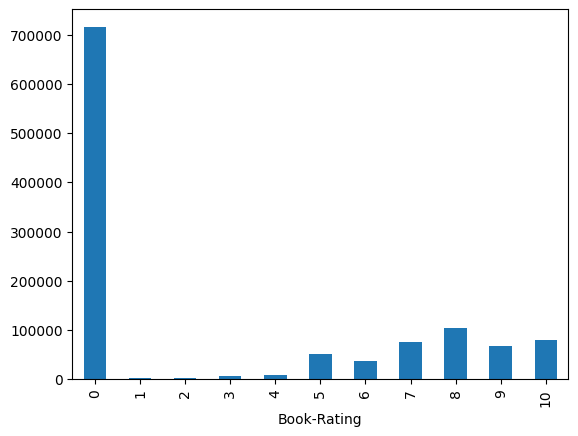

In [ ]:
ratings['Book-Rating'].value_counts().sort_index()
ratings['Book-Rating'].value_counts().sort_index().plot(kind='bar')

como é possível ver no resultado do snippet acima, a incidencia da nota 0 é extremamente grande, mas isso se deve a forma como o dataset foi montado, nesse caso o zero não significa uma nota zero explicita, significa apenas que o usuario teve interação com o livro mas não o avaliou explicitamente.

In [ ]:
isbn_valido = ratings['ISBN'].isin(books['ISBN'])
isbn_valido.value_counts()


ISBN
True     1031136
False     118644
Name: count, dtype: int64

In [ ]:
total = 1031136 + 118644
print(f"{118644/total*100:.1f}% dos ratings são órfãos (ISBN sem correspondência em Books)")

10.3% dos ratings são órfãos (ISBN sem correspondência em Books)


In [ ]:
print("", books[books['Book-Title'].str.contains('&amp;', na=False)].shape[0])

 4870


In [ ]:
print(":", books[books['Publisher'].str.contains('&amp;', na=False)].shape[0])


: 15791


15.791 registros em Publisher e 4.870 em Book-Title contêm a entidade HTML 
"&amp;" não decodificada (deveria ser apenas "&"), resultado de um parsing 
incorreto do CSV original. Serão substituídos por "&" antes da análise final.

In [ ]:
books['Book-Author'].isnull().sum()
books[books['Book-Author'].str.len() < 2].shape[0] if books['Book-Author'].dtype == 'object' else None

15

In [ ]:
print("Nulos:", books['Book-Author'].isnull().sum())
print("Nome muito curto (<2 chars):", books[books['Book-Author'].str.len() < 2].shape[0])

Nulos: 2
Nome muito curto (<2 chars): 15


Book-Author possui 2 valores nulos e 15 registros com nome suspeitosamente 
curto (<2 caracteres) em 271.360 livros — volume irrelevante, sem necessidade 
de tratamento robusto. Podem ser descartados ou preenchidos com "Unknown".

In [ ]:
(books['ISBN'] != books['ISBN'].str.strip()).sum()

np.int64(1)

In [ ]:
books[books['ISBN'] != books['ISBN'].str.strip()]

,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
111808,0486404242\t,War in Kind: And Other Poems (Dover Thrift Edi...,Stephen Crane,1998,Dover Publications,http://images.amazon.com/images/P/0486404242.0...,http://images.amazon.com/images/P/0486404242.0...,http://images.amazon.com/images/P/0486404242.0...


In [ ]:
books['ISBN'] = books['ISBN'].str.strip()
ratings['ISBN'] = ratings['ISBN'].str.strip()

1 ISBN em Books contém espaço em branco extra (início/fim), o que pode causar 
falha de correspondência em merges. Aplicado .str.strip() em ISBN de Books e 
Ratings como precaução.

In [ ]:
ratings['User-ID'].isin(users['User-ID']).value_counts()

User-ID
True    1149780
Name: count, dtype: int64

Todos os User-ID em Ratings existem em Users (1.149.780/1.149.780) — 
nenhum rating órfão por usuário, diferente do que ocorre com ISBN órfão 
(10.3% dos ratings referenciam livro inexistente em Books).

In [ ]:
books['Publisher'].value_counts().head(10)

Publisher
Harlequin                   7535
Silhouette                  4220
Pocket                      3905
Ballantine Books            3783
Bantam Books                3646
Scholastic                  3160
Simon &amp; Schuster        2971
Penguin Books               2844
Berkley Publishing Group    2771
Warner Books                2727
Name: count, dtype: int64

Publisher.value_counts() não revelou valores genéricos/placeholder no topo — 
as editoras mais frequentes são todas legítimas (Harlequin, Silhouette, Pocket, 
etc.), confirmando apenas o problema já identificado de "&amp;" não decodificado 
(ex: "Simon &amp; Schuster").

# TRATAMENTOS APLICADOS


In [ ]:
#criando uma copia de cada tabela
users_original = users.copy()
books_original = books.copy()
ratings_original = ratings.copy()

In [ ]:
import numpy as np


users['Age'] = users['Age'].apply(lambda x: x if 5 <= x <= 100 else np.nan)

No snippet acima, aplicamos um filtro para converter em nulas (NaN) as idades incongruentes (menores que 5 ou maiores que 100), mantendo o restante das linhas na tabela.

In [ ]:
books['Year-Of-Publication'] = pd.to_numeric(books['Year-Of-Publication'], errors='coerce')

Convertendo todos os dados da coluna Year of Publication pra numerico

In [ ]:
books['Year-Of-Publication'] = books['Year-Of-Publication'].apply(lambda x: x if 1800 <= x <= 2026 else np.nan)

aplicando um filtro pra permitir apenas livros publicados entre 1800 e 2026.

In [ ]:

location_split = users['Location'].str.split(',', n=2, expand=True)

users['City'] = location_split[0].str.strip()
users['State'] = location_split[1].str.strip()
users['Country'] = location_split[2].str.strip()

valores_invalidos = ['n/a', '', 'N/A', 'na', 'null', 'None']
users[['City', 'State', 'Country']] = users[['City', 'State', 'Country']].replace(valores_invalidos, np.nan)


A célula acima separa Location em City, State e Country, removendo espaços extras, e padroniza valores equivalentes a nulo (como n/a e string vazia) substituindo-os por NaN.

In [ ]:
books['Publisher'] = books['Publisher'].str.replace('&amp;', '&', regex=False)
books['Book-Title'] = books['Book-Title'].str.replace('&amp;', '&', regex=False)

A célula acima substitui a entidade HTML '&' (resultado de um parsing incorreto do CSV original) pelo caractere '&' nas colunas Publisher e Book-Title, corrigindo a formatação do texto.

In [ ]:
books['ISBN'] = books['ISBN'].str.strip()
ratings['ISBN'] = ratings['ISBN'].str.strip()

A célula acima tira espaços em branco extras dos ISBN das tabelas books e ratings, garantindo que nao ocorra um problema de merge.

In [ ]:
ratings = ratings[ratings['Book-Rating'] != 0]

A célula acima remove os ratings que são iguais a zero, que representam notas implicitas, mantendo apenas as explicitas (de 1 a 10)

In [ ]:
ratings = ratings[ratings['ISBN'].isin(books['ISBN'])]

A célula acima remove os ratings cujo ISBN não possui correspondência na tabela Books, eliminando os registros de avaliações de livros sem dados cadastrados.

In [ ]:
print("Users:", users.shape)
print("Books:", books.shape)
print("Ratings:", ratings.shape, "(era", ratings_original.shape[0], "antes)")

print("\nNulos Age:", users['Age'].isnull().sum())
print("Nulos Year:", books['Year-Of-Publication'].isnull().sum())

Users: (278858, 6)
Books: (271360, 8)
Ratings: (383843, 3) (era 1149780 antes)

Nulos Age: 112010
Nulos Year: 4634


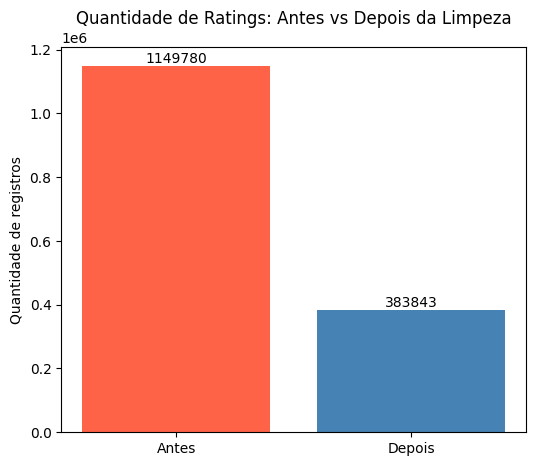

In [ ]:
import matplotlib.pyplot as plt

labels = ['Antes', 'Depois']
values = [ratings_original.shape[0], ratings.shape[0]]

plt.figure(figsize=(6, 5))
plt.bar(labels, values, color=['tomato', 'steelblue'])
plt.title('Quantidade de Ratings: Antes vs Depois da Limpeza')
plt.ylabel('Quantidade de registros')

for i, v in enumerate(values):
    plt.text(i, v + 10000, str(v), ha='center')

plt.show()

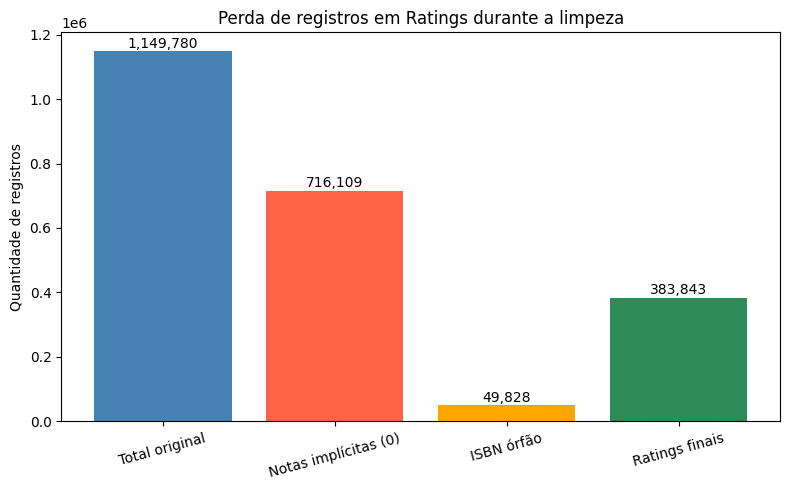

In [ ]:
import matplotlib.pyplot as plt

# quantidade perdida em cada etapa
total_original = ratings_original.shape[0]
implicitos = (ratings_original['Book-Rating'] == 0).sum()
sem_implicitos = ratings_original[ratings_original['Book-Rating'] != 0]
orfaos = (~sem_implicitos['ISBN'].isin(books['ISBN'])).sum()
final = ratings.shape[0]

labels = ['Total original', 'Notas implícitas (0)', 'ISBN órfão', 'Ratings finais']
values = [total_original, implicitos, orfaos, final]
colors = ['steelblue', 'tomato', 'orange', 'seagreen']

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, values, color=colors)
plt.title('Perda de registros em Ratings durante a limpeza')
plt.ylabel('Quantidade de registros')
plt.xticks(rotation=15)

for bar, v in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, v + 10000, f'{v:,}', ha='center')

plt.tight_layout()
plt.show()

Das 1.149.780 avaliações originais, 716.109 (62,3%) foram removidas por serem 
implícitas (nota 0), e mais 49.828 por referenciarem ISBN inexistente em Books 
(ISBN órfão calculado após remoção das implícitas, já que parte da sobreposição 
entre os dois problemas foi eliminada na primeira etapa). Restaram 383.843 
avaliações explícitas e válidas (33,4% da base original) para construção do 
sistema de recomendação.

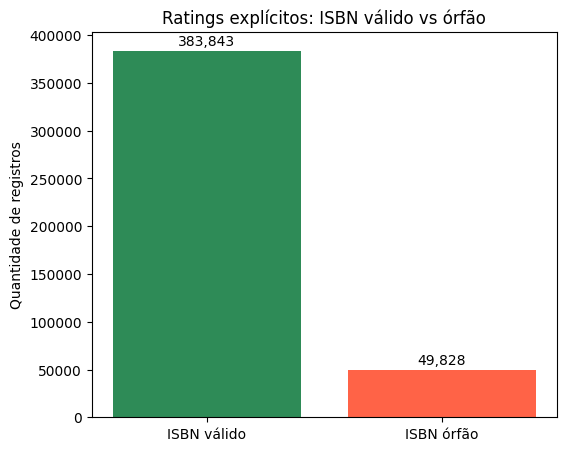

In [ ]:
import matplotlib.pyplot as plt

sem_implicitos = ratings_original[ratings_original['Book-Rating'] != 0]

isbns_validos = sem_implicitos['ISBN'].isin(books['ISBN']).sum()
isbns_orfaos = (~sem_implicitos['ISBN'].isin(books['ISBN'])).sum()

labels = ['ISBN válido', 'ISBN órfão']
values = [isbns_validos, isbns_orfaos]
colors = ['seagreen', 'tomato']

plt.figure(figsize=(6, 5))
bars = plt.bar(labels, values, color=colors)
plt.title('Ratings explícitos: ISBN válido vs órfão')
plt.ylabel('Quantidade de registros')

for bar, v in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, v + 5000, f'{v:,}', ha='center')

plt.show()

In [ ]:
users_original["Age"].value_counts().sort_index().head(10)

Age
0.0    416
1.0    288
2.0    105
3.0     45
4.0     28
5.0     26
6.0     18
7.0     27
8.0     54
9.0     62
Name: count, dtype: int64

In [ ]:

import surprise

#reader = Reader(rating_scale=(1, 10))
data = surprise.Dataset.load_from_df(
    ratings[['User-ID', 'ISBN', 'Book-Rating']], 
    
)

ImportError: cannot import name 'Reader' from 'io' (c:\Users\user\AppData\Local\Programs\Python\Python310\lib\io.py)